# 01 · Discovery — ¿con qué datos contamos?

**Fase:** puente F2 → F3 · **Lee:** `data/gold/flamesafe.duckdb` (solo lectura) · **No modifica datos.**

Este notebook es la puerta de entrada al análisis. No prueba hipótesis (eso es `02_eda/`); responde cuatro preguntas que el EDA
necesita resueltas antes de empezar:

1. **Inventario:** qué tablas gold hay, de qué investigaciones vienen y qué papel tiene cada una en el MVP (RQ5).
2. **Diseño experimental:** qué se varió y qué se mantuvo fijo en cada campaña. Esto define qué comparaciones son legítimas y qué
   variables están confundidas (EDA_PROTOCOL §1.4).
3. **Cobertura frente a los hábitats:** cuántas pruebas caen cerca de las atmósferas de la base lunar, el rover y Marte.
4. **Calidad y brechas:** faltantes estructurales vs. aleatorios, balance de clases y límites que el EDA debe declarar.

Además deja documentada la **evidencia interna para R-DE-05b** (unidad de la tasa de quemado de FLEX).

> **Reglas que aplican aquí** (CLAUDE.md): `zst` y `tad_k` son **calculadas**, no medidas; PSI **no tiene datos de gravedad
> parcial**, así que toda lectura lunar/marciana es un acotamiento; faltante = NULL, nunca 0.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from flamesafe import config
from flamesafe.physics.atmospheres import REFERENCE_ATMOSPHERES

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "axes.edgecolor": "#8a8984", "axes.labelcolor": "#2c2c2a", "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "font.size": 9})

# Fixed categorical order (validated reference palette, first three slots only: safe for scatter all-pairs)
OUTCOME_COLORS = {"yes": "#eb6834", "no": "#2a78d6", "flash": "#1baf7a"}
INK, MUTED = "#0b0b0b", "#8a8984"

DB = config.data_dir() / "gold" / "flamesafe.duckdb"
con = duckdb.connect(str(DB), read_only=True)


def q(sql):
    return con.sql(sql).df()


print(DB.name, "found:", DB.exists())  # avoid printing absolute local paths

flamesafe.duckdb found: True


## 1. Inventario de gold

Cinco tablas, construidas y validadas por `flamesafe gold` + `flamesafe validate` (gate G2). Cada fila conserva su procedencia
(`source_file`, `source_row`), así que cualquier punto de una gráfica se puede rastrear hasta el archivo PSI original.

In [2]:
tables = q("SELECT table_name FROM information_schema.tables WHERE table_schema = 'main' ORDER BY table_name").table_name
inventory = pd.DataFrame([
    {"table": t,
     "rows": q(f"SELECT count(*) AS n FROM {t}").n[0],
     "columns": len(q(f"DESCRIBE {t}"))}
    for t in tables
])
inventory

,table,rows,columns
0,droplet_reference_points,15861,22
1,droplet_tests,501,26
2,gas_flame_tests,660,32
3,investigations,24,56
4,publications,303,6


### 1.1 Qué investigaciones alimentan el análisis (vista RQ5)

`investigations` trae el puntaje de triage (R1–R6, `score`, `tier`), el papel en el MVP y cuántas pruebas aportó a gold.

In [3]:
inv = q('''
    SELECT psi_id, acronym, tier, round(score, 2) AS score, hardware_family, mvp_role, n_gold_tests,
           n_experimental_tables, n_publications, environments
    FROM investigations
    ORDER BY tier, score DESC
''')
inv

,psi_id,acronym,tier,score,hardware_family,mvp_role,n_gold_tests,n_experimental_tables,n_publications,environments
0,PSI-159,ACME CFI-G,1,1.00,CIR-ACME,RQ1,333,2,2,"nave, estacion, base_lunar, rover, marte"
1,PSI-69,FLEX,1,0.93,CIR-MDCA,RQ2,274,1,51,"nave, estacion, base_lunar, rover, marte"
2,PSI-10,ACME/Flame Design,1,0.93,CIR-ACME,RQ1,327,2,33,"nave, estacion, base_lunar, rover, marte"
3,PSI-101,SAME-R,1,0.92,CSD (SAME),NaN,0,1,6,"nave, estacion, base_lunar, rover"
4,PSI-39,CFI,1,0.90,CIR-MDCA,RQ2,227,1,7,"nave, estacion, base_lunar"
5,PSI-107,SPICE,1,0.82,MSG,NaN,0,1,9,"nave, estacion"
6,PSI-98,SAFFIRE-I,2,0.92,Saffire (Cygnus),NaN,0,1,6,"nave, estacion"
7,PSI-100,SAFFIRE-III,2,0.92,Saffire (Cygnus),NaN,0,1,3,"nave, estacion"
8,PSI-102,SAME,2,0.85,CSD (SAME),NaN,0,1,16,"nave, estacion, base_lunar, rover"
9,PSI-25,BASS-II,2,0.82,MSG,NaN,0,1,17,"nave, estacion, base_lunar, rover"


In [4]:
summary = (inv.assign(feeds_gold=inv.n_gold_tests > 0)
              .groupby("tier")
              .agg(investigations=("psi_id", "size"), feed_gold=("feeds_gold", "sum"),
                   gold_tests=("n_gold_tests", "sum"), publications=("n_publications", "sum")))
summary

,investigations,feed_gold,gold_tests,publications
tier,,,,
1,6,4,1161,108
2,8,0,0,71
3,10,0,0,173


**Lectura.** Las pruebas cuantitativas de gold salen de **cuatro investigaciones**: ACME Flame Design (PSI-10) y CFI-G (PSI-159)
para llamas de gas, y FLEX (PSI-69) y CFI (PSI-39) para gotas. El resto de Tier 1–2 aporta contexto, PDF y publicaciones (corpus del
RAG), no filas numéricas. Esto acota lo que el dashboard puede afirmar *con datos* frente a lo que solo puede *citar*.

## 2. Llamas de gas (`gas_flame_tests`, RQ1)

### 2.1 Composición: campaña × tipo de llama × combustible

In [5]:
g = q("SELECT * FROM gas_flame_tests")
pd.crosstab([g.campaign, g.flame_type], g.fuel, margins=True)

fuel                     butane  ethane  ethylene  propane  All
campaign     flame_type                                        
CFI-G        inverse         58      53         0       43  154
             normal          82      41         0       56  179
Flame Design inverse          0       0       120        0  120
             normal           0       0       187       20  207
All                         140      94       307      119  660

### 2.2 Variable de resultado y balance de clases

`ignition_outcome` tiene tres valores. Los **8 casos `flash`** (todos en CFI-G inversas) se mantienen como categoría propia:
**decisión PHY 2026-11-14** → excluirlos solo del ajuste binario principal de M1 y hacer análisis de sensibilidad (flash = sí /
flash = no). `ignited` ya es NULL para ellos en gold.

El origen del resultado importa: en CFI-G viene de la tabla experimental (`Hot ignition`, medido); en Flame Design viene de
`EventData` (`Ignite`, **decisión operativa**, R-DE-08a).

In [6]:
outcome = pd.crosstab([g.campaign, g.flame_type, g.outcome_source], g.ignition_outcome, margins=True)
outcome

ignition_outcome                            flash  no  yes  All
campaign     flame_type outcome_source                         
CFI-G        inverse    experimental_table      8  15  131  154
             normal     experimental_table      0  47  132  179
Flame Design inverse    eventdata               0   0  118  118
             normal     eventdata               0   2  205  207
All                                             8  64  586  658

In [7]:
fd_yes_rate = (g.loc[g.campaign == "Flame Design", "ignition_outcome"] == "yes").mean()
cfig = g[g.campaign == "CFI-G"]
print(f"Flame Design: share 'yes' = {fd_yes_rate:.1%}  -> near-constant, not a usable classification target")
print(f"CFI-G: yes={int((cfig.ignition_outcome == 'yes').sum())}, no={int((cfig.ignition_outcome == 'no').sum())}, "
      f"flash={int((cfig.ignition_outcome == 'flash').sum())}  -> M1 training set")

Flame Design: share 'yes' = 98.8%  -> near-constant, not a usable classification target
CFI-G: yes=263, no=62, flash=8  -> M1 training set


### 2.3 Diseño experimental: ¿qué se varió?

Mapa de condiciones en el plano (presión total, fracción de O₂), con las atmósferas de referencia superpuestas. Es la figura clave
para saber **si los hábitats caen dentro o fuera del dominio de los datos**.

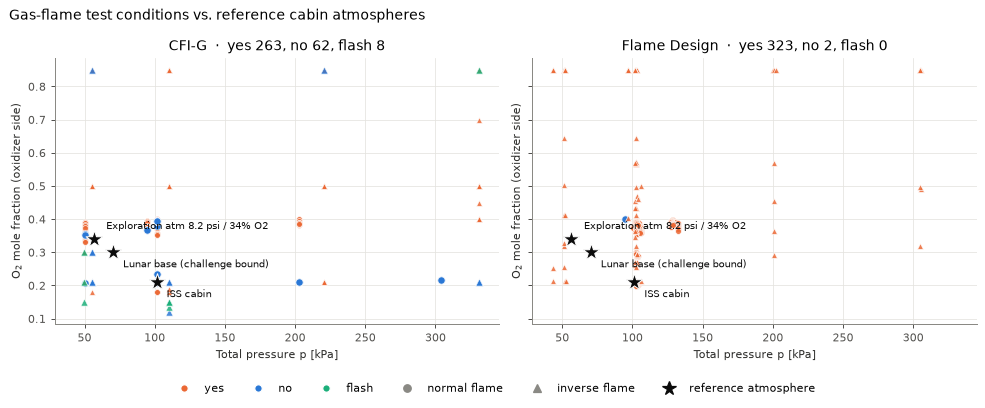

In [8]:
atm = pd.DataFrame([{"key": k, "name": a.name, "p_kpa": a.total_pressure_kpa, "xo2": a.o2_mole_fraction,
                     "po2_kpa": a.o2_partial_pressure_kpa, "gravity_g": a.gravity_g}
                    for k, a in REFERENCE_ATMOSPHERES.items()])
habitats = atm[atm.key.isin(["lunar_base_upper", "exploration_8p2_34", "iss_cabin"])]


def design_map(ax, df, title):
    for ft, marker in [("normal", "o"), ("inverse", "^")]:
        for oc in ["yes", "no", "flash"]:  # 'no' and 'flash' drawn on top so the minority classes stay visible
            s = df[(df.ignition_outcome == oc) & (df.flame_type == ft)]
            ax.scatter(s.p_kpa, s.xo2, s=22 if oc == "yes" else 34, marker=marker, c=OUTCOME_COLORS[oc],
                       edgecolors="white", linewidths=0.6, alpha=0.85)
    for _, h in habitats.iterrows():
        ax.scatter(h.p_kpa, h.xo2, marker="*", s=200, c=INK, edgecolors="white", linewidths=0.8, zorder=5)
        ax.annotate(h["name"], (h.p_kpa, h.xo2), xytext=LABEL_OFFSET[h.key], textcoords="offset points",
                    fontsize=8, color=INK, ha="right" if LABEL_OFFSET[h.key][0] < 0 else "left")
    counts = df.ignition_outcome.value_counts()
    ax.set(title=f"{title}  ·  " + ", ".join(f"{k} {counts.get(k, 0)}" for k in ["yes", "no", "flash"]),
           xlabel="Total pressure p [kPa]", ylabel="O$_2$ mole fraction (oxidizer side)")


LABEL_OFFSET = {"exploration_8p2_34": (10, 8), "lunar_base_upper": (8, -12), "iss_cabin": (8, -12)}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True, sharey=True)
for ax, (camp, df) in zip(axes, g.groupby("campaign"), strict=True):
    design_map(ax, df, camp)
from matplotlib.lines import Line2D  # noqa: E402

handles = ([Line2D([], [], ls="", marker="o", color=c, label=k, markeredgecolor="white") for k, c in OUTCOME_COLORS.items()]
           + [Line2D([], [], ls="", marker=m, color=MUTED, label=f"{ft} flame") for ft, m in [("normal", "o"), ("inverse", "^")]]
           + [Line2D([], [], ls="", marker="*", color=INK, markersize=11, label="reference atmosphere")])
fig.legend(handles=handles, loc="lower center", ncol=6, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Gas-flame test conditions vs. reference cabin atmospheres", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0.06, 1, 1))

In [9]:
design = (g.groupby(["campaign", "flame_type"])
            .agg(n=("test_id", "size"), test_days=("test_day", "nunique"),
                 xo2_levels=("xo2", lambda s: s.round(2).nunique()), xo2_min=("xo2", "min"), xo2_max=("xo2", "max"),
                 p_levels=("p_kpa", lambda s: s.round(0).nunique()), p_min=("p_kpa", "min"), p_max=("p_kpa", "max"),
                 fuels=("fuel", "nunique"), dilution_levels=("fuel_dilution_pct", "nunique"))
            .round(2))
design

n  test_days  xo2_levels  xo2_min  xo2_max  p_levels  p_min   p_max  fuels  dilution_levels
campaign     flame_type                                                                                               
CFI-G        inverse     154         12          12     0.12     0.85         5  49.54  330.99      3                1
             normal      179         11          12     0.18     0.40         5  50.67  303.99      3                3
Flame Design inverse     120          8          21     0.21     0.85        17  43.16  305.82      1                0
             normal      207         14           9     0.20     0.40        14  94.43  132.79      2                1

### 2.4 Confusores: ¿están O₂ y presión correlacionados por diseño?

H1 pregunta si la **presión parcial de O₂** explica la ignición mejor que la **fracción molar**. Eso solo se puede contestar si ambas
variables no son casi la misma cosa en los datos. `po2_kpa = xo2 · p_kpa` es derivada: si una campaña varió solo `xo2` a presión
fija, `po2` y `xo2` serán colineales y no se podrán separar.

In [10]:
def spearman_by(df, cols, by):
    rows = []
    for key, s in df.groupby(by):
        c = s[cols].corr(method="spearman")
        rows.append({by if isinstance(by, str) else "group": key, "n": len(s),
                     "rho(xo2, p)": c.loc["xo2", "p_kpa"], "rho(xo2, po2)": c.loc["xo2", "po2_kpa"],
                     "rho(p, po2)": c.loc["p_kpa", "po2_kpa"]})
    return pd.DataFrame(rows).round(2)


spearman_by(g.dropna(subset=["xo2", "p_kpa", "po2_kpa"]), ["xo2", "p_kpa", "po2_kpa"], "campaign")

,campaign,n,"rho(xo2, p)","rho(xo2, po2)","rho(p, po2)"
0,CFI-G,333,0.29,0.77,0.80
1,Flame Design,316,-0.10,0.82,0.38


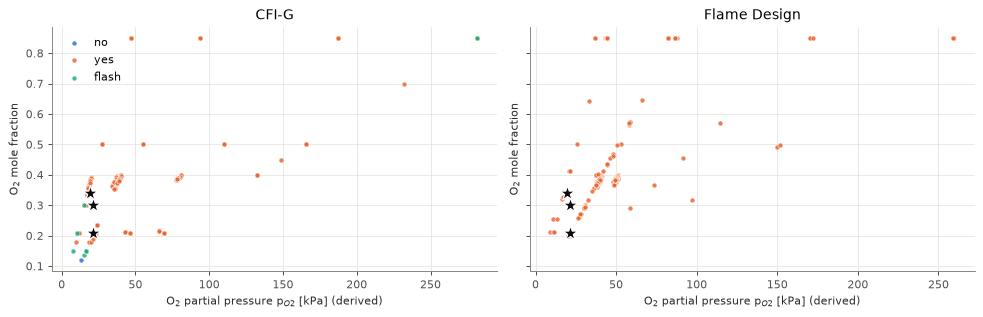

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (camp, df) in zip(axes, g.groupby("campaign"), strict=True):
    for oc in ["no", "yes", "flash"]:
        s = df[df.ignition_outcome == oc]
        ax.scatter(s.po2_kpa, s.xo2, s=16, c=OUTCOME_COLORS[oc], edgecolors="white", linewidths=0.5, alpha=0.85, label=oc)
    ax.scatter(habitats.po2_kpa, habitats.xo2, marker="*", s=160, c=INK, edgecolors="white", zorder=5)
    ax.set(title=camp, xlabel="O$_2$ partial pressure p$_{O2}$ [kPa] (derived)", ylabel="O$_2$ mole fraction")
axes[0].legend(frameon=False)
fig.tight_layout()

**Lectura.** `xo2` y `p_kpa` se variaron de forma casi independiente en ambas campañas (|ρ| ≤ 0.3), así que `po2` **no** es una
copia de `xo2`: H1 es contestable comparando modelos con `xo2` + `p` frente a `po2`. Aun así, ρ(xo2, po2) ≈ 0.8, y el EDA debe
reportar ese grado de colinealidad junto al resultado.

### 2.5 Faltantes: ¿estructurales o aleatorios?

Una columna vacía en una campaña entera es **estructural** (esa campaña no la mide) y no se imputa; una columna parcialmente vacía
dentro de una campaña sí requiere explicación. Las columnas de resultado secundarias (`extinction_mode`, `burn_time_s`,
`peak_burner_t_k`) son las que más afectan al EDA de RQ1.

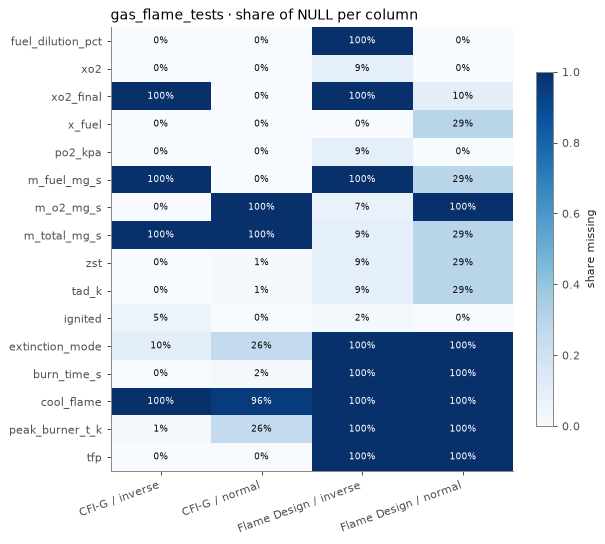

In [12]:
analysis_cols = ["fuel_dilution_pct", "xo2", "xo2_final", "x_fuel", "po2_kpa", "m_fuel_mg_s", "m_o2_mg_s", "m_total_mg_s",
                 "zst", "tad_k", "ignited", "extinction_mode", "burn_time_s", "cool_flame", "peak_burner_t_k", "tfp"]
miss_gas = g.groupby(["campaign", "flame_type"])[analysis_cols].agg(lambda s: s.isna().mean()).T.round(2)


def miss_heatmap(m, title):
    m = m.astype(float)
    fig, ax = plt.subplots(figsize=(1.6 + 1.3 * m.shape[1], 0.32 * m.shape[0] + 1))
    im = ax.imshow(m.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(m.shape[1]), [" / ".join(map(str, c)) if isinstance(c, tuple) else c for c in m.columns],
                  rotation=20, ha="right")
    ax.set_yticks(range(m.shape[0]), m.index)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m.values[i, j]
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7, color="white" if v > 0.6 else INK)
    ax.grid(False)
    ax.set_title(title, loc="left")
    fig.colorbar(im, ax=ax, fraction=0.04, label="share missing")
    fig.tight_layout()


miss_heatmap(miss_gas, "gas_flame_tests · share of NULL per column")

In [13]:
pd.crosstab([g.campaign, g.flame_type], g.extinction_mode.fillna("NULL"))

extinction_mode          NULL  flow_terminated  self_extinguished
campaign     flame_type                                          
CFI-G        inverse       15               58                 81
             normal        46               31                102
Flame Design inverse      120                0                  0
             normal       207                0                  0

**Lectura — hallazgo importante para el EDA.** Las variables de resultado secundarias (`extinction_mode`, `burn_time_s`,
`peak_burner_t_k`, `tfp`) **solo existen en CFI-G**. En gold, Flame Design aporta las condiciones, las variables calculadas
(`zst`, `tad_k`) y un resultado de ignición casi siempre "yes". Su valor es de **soporte positivo**: confirma que hubo llama en un
dominio amplio de (p, xo2), incluso cerca de los hábitats, pero no sirve para estimar una frontera ni para estudiar la extinción.
`cool_flame` está vacía en casi todo gold y no se analiza.

## 3. Cobertura cerca de los hábitats

¿Cuántas pruebas hay *cerca* de cada atmósfera de referencia? Ventana declarada antes de mirar: **|Δxo2| ≤ 0.05** y **presión
dentro de ±25 %** del valor del hábitat. Es solo un conteo de soporte; no es un modelo.

> ⚠️ Los hábitats lunar (0.165 g) y marciano (0.38 g) tienen gravedad parcial. PSI son datos de **microgravedad**: cualquier
> resultado cerca de estas estrellas acota el caso µg, no lo reproduce.

In [14]:
DX, DP = 0.05, 0.25


def near(df, xcol, h):
    return df[(df[xcol] - h.xo2).abs().le(DX) & ((df.p_kpa / h.p_kpa) - 1).abs().le(DP)]


rows = []
for _, h in atm.iterrows():
    s = near(g, "xo2", h)
    rows.append({"atmosphere": h["name"], "p_kpa": round(h.p_kpa, 1), "xo2": h.xo2, "gravity_g": h.gravity_g,
                 "n_tests": len(s), "n_campaigns": s.campaign.nunique(), "n_test_days": s.test_day.nunique(),
                 "yes": int((s.ignition_outcome == "yes").sum()), "no": int((s.ignition_outcome == "no").sum()),
                 "flash": int((s.ignition_outcome == "flash").sum())})
habitat_support = pd.DataFrame(rows)
habitat_support

,atmosphere,p_kpa,xo2,gravity_g,n_tests,n_campaigns,n_test_days,yes,no,flash
0,Earth sea level,101.4,0.209,1.000,118,2,10,104,14,0
1,ISS cabin,101.4,0.210,0.000,118,2,10,104,14,0
2,Spacesuit (EMU-class),29.6,1.000,0.000,0,0,0,0,0,0
3,Lunar base (challenge bound),70.3,0.300,0.165,6,1,3,4,2,0
4,Exploration atm 8.2 psi / 34% O2,56.5,0.340,0.165,30,2,6,24,5,1
5,Mars habitat (assumed = exploration atm),56.5,0.340,0.380,30,2,6,24,5,1


**Cómo leerlo.** La Tierra y la ISS comparten atmósfera, igual que el hábitat marciano y la atmósfera de exploración (supuesto
documentado en `atmospheres.py`), así que sus filas coinciden. El **traje espacial** (100 % O₂ a ~30 kPa) queda **fuera** del dominio
de los datos (xo2 ≤ 0.85, p ≥ 43 kPa): sobre él no se puede decir nada con gold. Un hábitat con pocas pruebas cercanas o con un solo resultado (todo "yes") no permite estimar una frontera de
ignición *en ese punto*: el modelo M1 interpolará desde condiciones vecinas y debe mostrar esa incertidumbre (y avisar si está
fuera del rango de entrenamiento). La celda de la tabla siguiente muestra los combustibles de esas pruebas, porque la frontera
depende del combustible.

In [15]:
pd.DataFrame({h["name"]: near(g, "xo2", h).groupby(["campaign", "fuel"]).size() for _, h in atm.iterrows()}).fillna(0).astype(int)

Earth sea level  ISS cabin  Spacesuit (EMU-class)  Lunar base (challenge bound)  Exploration atm 8.2 psi / 34% O2  \
campaign     fuel                                                                                                                          
CFI-G        butane                 12         12                      0                             3                                16   
             ethane                 15         15                      0                             1                                10   
             propane                17         17                      0                             2                                 2   
Flame Design ethylene               74         74                      0                             0                                 2   

                       Mars habitat (assumed = exploration atm)  
campaign     fuel                                                
CFI-G        butane                                          16  
             ethane                                          10  
             propane                                          2  
Flame Design ethylene                                         2

## 4. Gotas (`droplet_tests`, RQ2)

### 4.1 Composición y diseño

In [16]:
d = q("SELECT * FROM droplet_tests")
d["diluent"] = np.select([d.x_co2.fillna(0) > 0, d.x_he > 0], ["CO2", "He"], default="N2 only")
pd.crosstab([d.campaign, d.fuel], d.diluent, margins=True)

diluent                       CO2   He  N2 only  All
campaign fuel                                       
CFI      C12H26                 0   23       57   80
         C12H26/iso-dodecane    0   29       74  103
         farnesane              0    0       44   44
FLEX     heptane               48   22       47  117
         methanol              75   28       54  157
All                           123  102      276  501

In [17]:
(d.groupby("campaign")
  .agg(n=("test_id", "size"), test_dates=("test_date", "nunique"),
       p_min=("p_kpa", "min"), p_max=("p_kpa", "max"), xo2_min=("x_o2", "min"), xo2_max=("x_o2", "max"),
       xco2_max=("x_co2", "max"), xhe_max=("x_he", "max"), d0_min=("d0_mm", "min"), d0_max=("d0_mm", "max"))
  .round(3))

,n,test_dates,p_min,p_max,xo2_min,xo2_max,xco2_max,xhe_max,d0_min,d0_max
campaign,,,,,,,,,,
CFI,227,53,50.662,506.625,0.17,0.21,0.0,0.59,3.793,6.447
FLEX,274,80,70.168,309.295,0.12,0.34,0.7,0.45,1.100,4.670


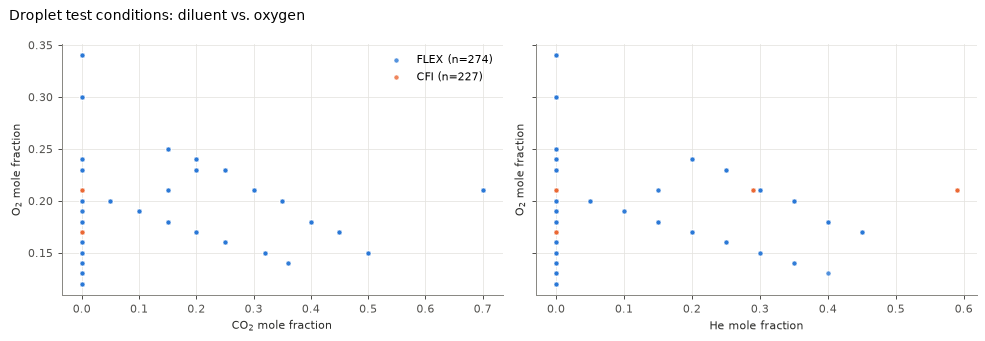

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, xcol, lab in [(axes[0], "x_co2", "CO$_2$ mole fraction"), (axes[1], "x_he", "He mole fraction")]:
    for camp, color in [("FLEX", "#2a78d6"), ("CFI", "#eb6834")]:
        s = d[d.campaign == camp]
        ax.scatter(s[xcol], s.x_o2, s=16, c=color, edgecolors="white", linewidths=0.5, alpha=0.8, label=f"{camp} (n={len(s)})")
    ax.set(xlabel=lab, ylabel="O$_2$ mole fraction")
axes[0].legend(frameon=False)
fig.suptitle("Droplet test conditions: diluent vs. oxygen", x=0.01, ha="left")
fig.tight_layout()

### 4.2 Resultados disponibles por campaña

Las dos campañas **no miden lo mismo**: FLEX registra cómo terminó la prueba (`test_end`) y una tasa de quemado; CFI registra
k y diámetro de extinción en fase caliente **y fría** (cool flame). Los faltantes de 100 % son estructurales.

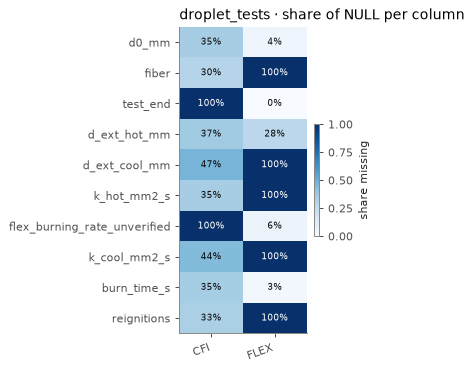

In [19]:
drop_cols = ["d0_mm", "fiber", "test_end", "d_ext_hot_mm", "d_ext_cool_mm", "k_hot_mm2_s", "flex_burning_rate_unverified",
             "k_cool_mm2_s", "burn_time_s", "reignitions"]
miss_heatmap(d.groupby("campaign")[drop_cols].agg(lambda s: s.isna().mean()).T.round(2), "droplet_tests · share of NULL per column")

In [20]:
pd.crosstab([d.fuel, d.diluent], d.test_end.fillna("NULL (CFI)"), margins=True)

test_end                     NULL (CFI)  completion  disruption  extinction  All
fuel                diluent                                                     
C12H26              He               23           0           0           0   23
                    N2 only          57           0           0           0   57
C12H26/iso-dodecane He               29           0           0           0   29
                    N2 only          74           0           0           0   74
farnesane           N2 only          44           0           0           0   44
heptane             CO2               0           3          18          27   48
                    He                0           6           2          14   22
                    N2 only           0          10          18          19   47
methanol            CO2               0           5           9          61   75
                    He                0           0           2          26   28
                    N2 only           0           3          12          39   54
All                                 227          27          61         186  501

## 5. Evidencia interna para R-DE-05b: ¿la tasa de FLEX está en mm²/s?

**Decisión PHY (2026-11-14): sí, mm²/s.** Aquí dejamos la comprobación con los propios datos, independiente del encabezado.

Si la "tasa de quemado" es la constante K de la ley d² (d² = d₀² − K·t), entonces una estimación gruesa e independiente es
**K̂ = (d₀² − d_ext²) / t_quemado**, usando solo diámetros y tiempo medidos en la misma prueba. Si la columna estuviera en mm (un
diámetro o una velocidad lineal), no tendría por qué parecerse a K̂. Se espera K̂ algo **menor** que K porque t_quemado incluye el
calentamiento inicial, cuando la gota casi no se encoge.

Hacemos la misma comprobación en CFI, cuyo `k_hot_mm2_s` sí tiene la unidad confirmada, como control.

In [21]:
def k_check(df, kcol):
    s = df.assign(k_est=(df.d0_mm**2 - df.d_ext_hot_mm**2) / df.burn_time_s).dropna(subset=["k_est", kcol])
    ratio = s[kcol] / s.k_est
    return s, {"n": len(s), "median_k_reported": s[kcol].median(), "median_k_est": s.k_est.median(),
               "median_ratio": ratio.median(), "iqr_ratio": f"{ratio.quantile(.25):.2f}–{ratio.quantile(.75):.2f}",
               "spearman": s[[kcol, "k_est"]].corr(method="spearman").iloc[0, 1],
               "k_est<=0 (d_ext >= d0)": int((s.k_est <= 0).sum())}


flex_s, flex_r = k_check(d[d.campaign == "FLEX"], "flex_burning_rate_unverified")
cfi_s, cfi_r = k_check(d[d.campaign == "CFI"], "k_hot_mm2_s")
pd.DataFrame({"FLEX (unit under test)": flex_r, "CFI (control, mm²/s)": cfi_r}).T.round(3)

,n,median_k_reported,median_k_est,median_ratio,iqr_ratio,spearman,k_est<=0 (d_ext >= d0)
FLEX (unit under test),196,0.48,0.451521,1.050927,1.03–1.09,0.963421,1
"CFI (control, mm²/s)",144,0.3325,0.277523,1.20867,1.02–1.40,0.738139,8


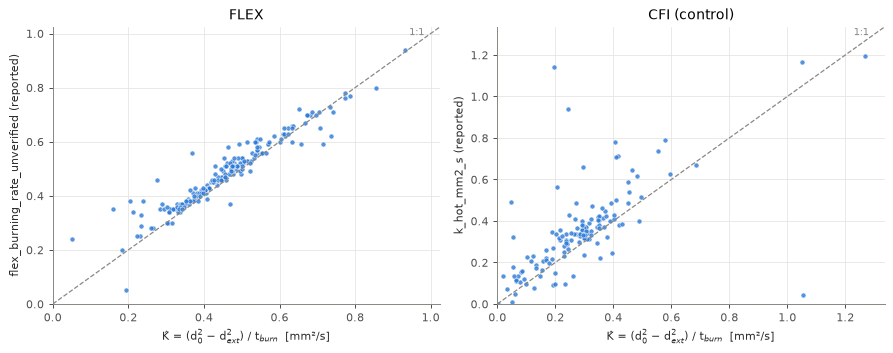

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (s, kcol, title) in zip(axes, [(flex_s, "flex_burning_rate_unverified", "FLEX"),
                                       (cfi_s, "k_hot_mm2_s", "CFI (control)")], strict=True):
    s = s[s.k_est > 0]
    ax.scatter(s.k_est, s[kcol], s=16, c="#2a78d6", edgecolors="white", linewidths=0.5, alpha=0.8)
    lim = [0, float(np.nanpercentile(np.r_[s.k_est, s[kcol]], 99)) * 1.1]
    ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
    ax.annotate("1:1", (lim[1] * 0.92, lim[1] * 0.97), color=MUTED, fontsize=8)
    ax.set(xlim=lim, ylim=lim, title=title, xlabel="K̂ = (d$_0^2$ − d$_{ext}^2$) / t$_{burn}$  [mm²/s]",
           ylabel=f"{kcol} (reported)")
fig.tight_layout()

**Conclusión.** La tasa de FLEX sigue a K̂ prácticamente sobre la línea 1:1, con una relación monótona casi perfecta y el sesgo
esperado (cociente ligeramente > 1, por el calentamiento). El control de CFI muestra el mismo sesgo hacia > 1 con más dispersión
(sus pruebas incluyen fase fría y fibras), lo que confirma que el método reconoce una columna en mm²/s. Junto con la decisión PHY, esto basta para **cerrar R-DE-05b**: el siguiente cambio del pipeline (ADR-0004) pasa la columna a `k_hot_mm2_s`.

Los casos con K̂ ≤ 0 (d_ext ≥ d₀) no invalidan la conclusión, pero son **pruebas a revisar** en el EDA (posible hinchamiento
térmico o diámetro final mal medido), igual que CFI 1274A en el reporte gold.

## 6. Material de validación y corpus

`droplet_reference_points` (PSI-117) son puntos digitalizados de figuras publicadas: **experimento, modelo y barras de error**. No
son pruebas independientes; sirven para validar M2 y las curvas del EDA contra la literatura. `publications` es la base del RAG.

In [23]:
q('''
    SELECT role, count(*) AS points, count(DISTINCT data_file) AS data_files, count(DISTINCT figure) AS figures,
           count(DISTINCT doi) AS dois
    FROM droplet_reference_points GROUP BY role ORDER BY points DESC
''')

,role,points,data_files,figures,dois
0,unknown,11545,5,3,3
1,model,4237,6,6,2
2,experiment,69,4,4,2
3,error_bar,10,1,1,1


La mayoría de los puntos tiene rol `unknown` (series sin leyenda clara en el archivo fuente). Para validar se usan solo los roles
`experiment` y `model`; los `unknown` necesitan revisión manual de la figura antes de usarse.

In [24]:
q('''
    SELECT status, count(*) AS publications, count(doi) AS with_doi, round(avg(n_records), 2) AS avg_psi_records
    FROM publications GROUP BY status ORDER BY publications DESC
''')

,status,publications,with_doi,avg_psi_records
0,published,303,235,1.16


## 7. Qué significa esto para el EDA

Resumen automático de los números que condicionan el EDA (se recalcula al ejecutar):

In [25]:
facts = {
    "gas tests (total)": len(g),
    "M1 binary training set (CFI-G yes+no)": int(cfig.ignition_outcome.isin(["yes", "no"]).sum()),
    "flash cases (sensitivity only)": int((g.ignition_outcome == "flash").sum()),
    "Flame Design share 'yes'": f"{fd_yes_rate:.1%}",
    "gas test days (CV groups)": int(g.groupby("campaign").test_day.nunique().sum()),
    "gas tests near lunar bound (±0.05 xo2, ±25% p)": int(habitat_support.loc[habitat_support.atmosphere.str.startswith("Lunar"), "n_tests"].iloc[0]),
    "droplet tests (total)": len(d),
    "droplet tests with CO2 / He": f"{int((d.diluent == 'CO2').sum())} / {int((d.diluent == 'He').sum())}",
    "FLEX rate vs K̂ median ratio": round(flex_r["median_ratio"], 3),
    "droplet tests with d_ext >= d0 (to review)": flex_r["k_est<=0 (d_ext >= d0)"] + cfi_r["k_est<=0 (d_ext >= d0)"],
}
pd.Series(facts, name="value").to_frame()

,value
gas tests (total),660
M1 binary training set (CFI-G yes+no),325
flash cases (sensitivity only),8
Flame Design share 'yes',98.8%
gas test days (CV groups),26
"gas tests near lunar bound (±0.05 xo2, ±25% p)",6
droplet tests (total),501
droplet tests with CO2 / He,123 / 102
FLEX rate vs K̂ median ratio,1.051
droplet tests with d_ext >= d0 (to review),9


Conclusiones para planear `02_eda/` (los números exactos están en las celdas de arriba):

- **RQ1 se analiza con CFI-G**: es la única campaña con ignición binaria balanceada y con resultados de extinción
  (`extinction_mode`, `burn_time_s`, `peak_burner_t_k`). Flame Design entra como soporte positivo ("hubo llama aquí") y para las
  variables calculadas, nunca como clase negativa.
- **Separar normal e inversa siempre.** En las inversas el O₂ sale del quemador y `xo2` significa otra cosa (PHY-04). Mezclarlas
  viola la regla de no combinar variables no comparables.
- **El combustible es un estrato obligatorio** (etileno solo en Flame Design; etano, propano y butano en CFI-G).
- **La validación cruzada se agrupa por `test_day`** dentro de cada campaña, no por prueba, para no inflar el desempeño.
- **H1 (po2 vs xo2) es contestable**, porque `xo2` y `p` se variaron casi de forma independiente (§2.4); reportar la colinealidad.
- **Faltantes estructurales no se imputan.** `extinction_mode`, `burn_time_s` y `peak_burner_t_k` existen solo en parte del diseño;
  cada análisis declara su subconjunto y su n.
- **RQ2 compara diluyentes dentro de FLEX** (CO₂ y He con heptano y metanol); CFI aporta presión alta y fase fría. Al cerrar R-DE-05b
  ambas campañas comparten `k_hot_mm2_s`, pero el combustible y la fibra se tratan como estratos.
- **La base lunar y la atmósfera de exploración caen dentro del dominio (p, xo2)**, pero con soporte local escaso (pocas pruebas
  y pocos "no" cerca) y siempre en µg; el traje espacial queda fuera. El dashboard debe mostrar incertidumbre, la advertencia de
  fuera de rango y la etiqueta de extrapolación de gravedad.

In [26]:
con.close()